# Lab 3: Нейронні мережі для табличних даних, зображень і текстів

**Мета роботи:** Ознайомитися з базовим workflow побудови та навчання нейронних мереж для різних типів даних: табличних даних, зображень і текстів; дослідити процес навчання моделей та порівняти нейромережеві підходи з класичними алгоритмами машинного навчання.

## Підготовка

In [1]:
import gzip
import hashlib
import html
import random
import re
import time
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


def clean_axes(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.grid(color='#e5e4e0', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # епохи - цілі числа

Device: cpu


Функції навчання спільні для всіх трьох завдань, тому визначаємо їх один раз. train_one_epoch проходить по всіх батчах тренувальних даних, рахує функцію втрат і оновлює ваги, а evaluate_one_epoch лише рахує втрати на валідаційних даних без оновлення ваг. fit повторює обидва кроки задану кількість епох і зберігає історію втрат, з якої потім будуємо learning curves. predict повертає справжні й передбачені мітки для підрахунку метрик.

In [2]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    train_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    return train_loss / len(loader)


def evaluate_one_epoch(model, loader, criterion, device):
    model.eval()
    valid_loss = 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            valid_loss += criterion(out, y).item()
    return valid_loss / len(loader)


def fit(model, train_loader, val_loader, optimizer, criterion, n_epochs, print_every=1):
    history = {'train_loss': [], 'val_loss': []}
    start = time.perf_counter()
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss = evaluate_one_epoch(model, val_loader, criterion, device)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        if (epoch + 1) % print_every == 0 or epoch == 0:
            print(f'[{epoch + 1:02d}] train_loss={train_loss:.4f} | val_loss={val_loss:.4f}')
    history['time'] = time.perf_counter() - start
    print(f'Час навчання: {history["time"]:.0f} с')
    return history


@torch.no_grad()
def predict(model, loader, device):
    model.eval()
    y_true, y_pred = [], []
    for x, y in loader:
        out = model(x.to(device))
        pred = out.argmax(dim=1) if out.ndim == 2 else (out > 0).long()
        y_true.append(y.cpu())
        y_pred.append(pred.cpu())
    return torch.cat(y_true).long().numpy(), torch.cat(y_pred).numpy()


def plot_curves(ax, history, title):
    epochs = range(1, len(history['train_loss']) + 1)
    ax.plot(epochs, history['train_loss'], color='#2a78d6', linewidth=2, label='train loss')
    ax.plot(epochs, history['val_loss'], color='#eb6834', linewidth=2, label='validation loss')
    ax.set_title(title, loc='left', fontsize=12)
    ax.set_xlabel('епоха')
    ax.set_ylabel('loss')
    ax.legend(frameon=False)
    clean_axes(ax)

## 1) Повнозв'язані нейронні мережі

### Дані з Lab 1

Повторюємо підготовку з Lab 1. Завантажуємо 11 CSV-файлів N-BaIoT (пристрій Danmini_Doorbell), видаляємо дублікати, кодуємо класи, беремо по 3000 записів на клас і ділимо на train і test 80/20 зі стратифікацією та random_state=42. Розбиття те саме, що в Lab 1, тому результати можна порівнювати напряму.

Для learning curves потрібні ще й **валідаційні дані**, на яких модель не вчиться, але які й не є тестовими. Тому від train відкладаємо ще 20 % на validation. Test використовуємо лише один раз, для фінальної оцінки.

In [3]:
DATA_DIR = Path("../detection+of+iot+botnet+attacks+n+baiot/Danmini_Doorbell")


def load_csv(path, category, label):
    part = pd.read_csv(path).copy()
    part['category'] = category
    part['label'] = label
    return part


parts = [load_csv(DATA_DIR / 'benign_traffic.csv', 'benign', 'benign')]
for f in sorted((DATA_DIR / 'gafgyt_attacks').rglob('*.csv')):
    parts.append(load_csv(f, 'gafgyt', 'gafgyt_' + f.stem))
for f in sorted((DATA_DIR / 'mirai_attacks').rglob('*.csv')):
    parts.append(load_csv(f, 'mirai', 'mirai_' + f.stem))

df = pd.concat(parts, ignore_index=True).drop_duplicates(ignore_index=True)
del parts
feature_cols = [c for c in df.columns if c not in ('category', 'label')]

le = LabelEncoder()
df['label_Encoded'] = le.fit_transform(df['label'])

df_bal = df.groupby('label').sample(n=3000, random_state=42).reset_index(drop=True)
X = df_bal[feature_cols]
y = df_bal['label_Encoded']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
print('Train:', X_tr.shape, ' Validation:', X_val.shape, ' Test:', X_test.shape)

Train: (21120, 115)  Validation: (5280, 115)  Test: (6600, 115)


Ознаки масштабуємо через StandardScaler, як для kNN і SVM у Lab 1. Нейронна мережа теж чутлива до масштабу, бо ваги навчаються градієнтним спуском, і ознаки з величезними значеннями забирали б на себе весь градієнт. Scaler навчаємо лише на train. Потім перетворюємо дані в тензори PyTorch і загортаємо в DataLoader, який подає їх моделі батчами по 128 записів і перемішує train перед кожною епохою.

In [4]:
scaler = StandardScaler().fit(X_tr)


def to_tensors(X_part, y_part):
    X_t = torch.tensor(scaler.transform(X_part), dtype=torch.float32)
    y_t = torch.tensor(y_part.values, dtype=torch.long)
    return TensorDataset(X_t, y_t)


train_loader = DataLoader(to_tensors(X_tr, y_tr), batch_size=128, shuffle=True)
val_loader = DataLoader(to_tensors(X_val, y_val), batch_size=1024)
test_loader = DataLoader(to_tensors(X_test, y_test), batch_size=1024)

x_batch, y_batch = next(iter(train_loader))
print('Один батч:', x_batch.shape, y_batch.shape)

Один батч: torch.Size([128, 115]) torch.Size([128])


### Модель MLP

**MLP (Multilayer Perceptron)** складається з кількох повнозв'язаних шарів. Кожен нейрон шару отримує всі виходи попереднього шару, рахує їхню зважену суму і пропускає її через функцію активації. У нас 115 входів (ознаки трафіку), два приховані шари на 128 і 64 нейрони з активацією ReLU і вихідний шар на 11 нейронів, по одному на клас. ReLU (max(0, x)) робить мережу нелінійною, без неї кілька шарів зводилися б до одного лінійного перетворення.

Вихідний шар повертає логіти, тобто «сирі» оцінки кожного класу. CrossEntropyLoss сама застосовує до них softmax і порівнює отримані ймовірності зі справжнім класом, тому окремий softmax у моделі не потрібен. Ваги оптимізує Adam з кроком навчання 0.001.

In [5]:
class BotnetMLP(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.net(x)


set_seed(42)
mlp = BotnetMLP(len(feature_cols), len(le.classes_)).to(device)
print(mlp)
print('Параметрів:', sum(p.numel() for p in mlp.parameters()))

BotnetMLP(
  (net): Sequential(
    (0): Linear(in_features=115, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=11, bias=True)
  )
)
Параметрів: 23819


In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)
history_mlp = fit(mlp, train_loader, val_loader, optimizer, criterion, n_epochs=50, print_every=5)

[01] train_loss=0.8465 | val_loss=0.4367
[05] train_loss=0.3131 | val_loss=0.3106
[10] train_loss=0.2655 | val_loss=0.2754
[15] train_loss=0.2063 | val_loss=0.2152
[20] train_loss=0.1724 | val_loss=0.1957
[25] train_loss=0.1601 | val_loss=0.1729
[30] train_loss=0.1645 | val_loss=0.1774
[35] train_loss=0.1472 | val_loss=0.1750
[40] train_loss=0.1481 | val_loss=0.1810
[45] train_loss=0.1432 | val_loss=0.1614
[50] train_loss=0.1462 | val_loss=0.1940
Час навчання: 18 с


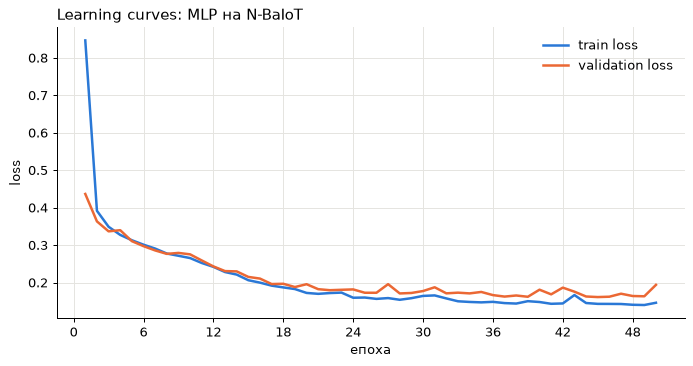

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2), dpi=90)
plot_curves(ax, history_mlp, 'Learning curves: MLP на N-BaIoT')
plt.show()

Обидві криві різко падають за перші 5 епох, потім знижуються повільніше і після 25-ї епохи виходять на рівень приблизно 0.15-0.20. Train loss і validation loss весь час ідуть поруч, і розрив між ними не росте, тому **перенавчання немає**. На даних, яких модель не бачила, вона помиляється так само, як на тренувальних. Окремі стрибки validation loss (наприклад, на 27-й і 50-й епохах) пояснюються тим, що крок Adam 0.001 доволі великий і ваги трохи коливаються біля мінімуму.

Водночас loss не опускається до нуля, як було б у моделі, що ідеально розділяє класи. Отже, якусь частину даних MLP розділити не може, і причину видно в оцінці на test.

### Оцінка на test

In [8]:
y_true_mlp, y_pred_mlp = predict(mlp, test_loader, device)
print(f'Accuracy: {accuracy_score(y_true_mlp, y_pred_mlp):.4f}   macro F1: {f1_score(y_true_mlp, y_pred_mlp, average="macro"):.4f}\n')
print(classification_report(y_true_mlp, y_pred_mlp, target_names=le.classes_, digits=4, zero_division=0))


def top_confusions(y_true, y_pred, names, n=5):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(names)))
    pairs = [(names[i], names[j], cm[i, j]) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j] > 0]
    pairs = pd.DataFrame(pairs, columns=['справжній клас', 'передбачений клас', 'кількість'])
    return pairs.sort_values('кількість', ascending=False).head(n)


print(top_confusions(y_true_mlp, y_pred_mlp, le.classes_).to_string(index=False))

Accuracy: 0.8915   macro F1: 0.8611

                precision    recall  f1-score   support

        benign     0.9983    0.9983    0.9983       600
  gafgyt_combo     1.0000    0.8250    0.9041       600
   gafgyt_junk     0.8499    1.0000    0.9188       600
   gafgyt_scan     0.9983    0.9967    0.9975       600
    gafgyt_tcp     0.5000    0.9983    0.6663       600
    gafgyt_udp     0.0000    0.0000    0.0000       600
     mirai_ack     0.9983    0.9900    0.9941       600
    mirai_scan     1.0000    1.0000    1.0000       600
     mirai_syn     1.0000    1.0000    1.0000       600
     mirai_udp     0.9884    0.9983    0.9934       600
mirai_udpplain     0.9983    1.0000    0.9992       600

      accuracy                         0.8915      6600
     macro avg     0.8483    0.8915    0.8611      6600
  weighted avg     0.8483    0.8915    0.8611      6600

справжній клас передбачений клас  кількість
    gafgyt_udp        gafgyt_tcp        599
  gafgyt_combo       gafgyt_junk

На test MLP має accuracy 0.892 і macro F1 0.861. Для 9 класів з 11 F1 становить від 0.90 до 1.0, а майже всі помилки зосереджені в парі gafgyt_tcp і gafgyt_udp. 599 із 600 записів gafgyt_udp модель віднесла до gafgyt_tcp, тому recall для udp дорівнює 0, а precision для tcp лише 0.5.

Це та сама картина, що й у SVM з Lab 1. Там ми з'ясували, що за характеристиками трафіку ці дві атаки не відрізняються, а дерева розділяють їх лише за ознаками **HH_jit**, які містять Unix-час запису (udp записали до 20.09.2017 13:18, tcp після). Після StandardScaler значення часу в обох класах збігаються до 6-го знака після коми, тому MLP, як і SVM, цієї різниці не бачить. Друга за кількістю помилка, 105 записів gafgyt_combo, передбачених як gafgyt_junk, теж знайома з Lab 1, бо ці дві атаки генерують дуже схожий трафік.

### Порівняння з класичними алгоритмами з Lab 1

Результати класичних моделей беремо з Lab 1 (те саме розбиття і той самий test).

In [9]:
mlp_acc = accuracy_score(y_true_mlp, y_pred_mlp)
comparison = pd.DataFrame({
    'accuracy на test': {
        'Random Forest': 0.9995,
        'AdaBoost (глибина 5)': 0.9988,
        'Decision Tree': 0.9983,
        'kNN (k = 1)': 0.9947,
        'SVM (C = 1000, gamma = 1)': 0.9036,
        'MLP (PyTorch)': mlp_acc,
    }
}).sort_values('accuracy на test', ascending=False)
comparison.round(4)

,accuracy на test
Random Forest,0.9995
AdaBoost (глибина 5),0.9988
Decision Tree,0.9983
kNN (k = 1),0.9947
"SVM (C = 1000, gamma = 1)",0.9036
MLP (PyTorch),0.8915


MLP поступається всім класичним моделям з Lab 1 і опиняється на останньому місці, трохи нижче SVM (0.892 проти 0.904). Обидві ці моделі вчаться на масштабованих ознаках і не розрізняють gafgyt_tcp і gafgyt_udp, тому їхня accuracy обмежена рівнем близько 0.91, тобто 10 правильних класів з 11. Дерева ж розділяють цю пару за порогом часу запису, тобто за артефактом датасету, а не за поведінкою трафіку. Тому основна частина різниці в accuracy показує не те, що MLP гірше розуміє трафік, а те, що дерева скористалися цим артефактом.

Перевіримо це пояснення. Об'єднаємо gafgyt_tcp і gafgyt_udp в один клас і навчимо таку саму MLP з тими самими параметрами. Якщо низька точність пояснюється лише цією парою, на 10 класах MLP має вийти на рівень класичних моделей.

In [10]:
tcp, udp = list(le.classes_).index('gafgyt_tcp'), list(le.classes_).index('gafgyt_udp')
merge = lambda s: s.replace(udp, tcp)

set_seed(42)
mlp_merged = BotnetMLP(len(feature_cols), len(le.classes_)).to(device)
train_loader_m = DataLoader(to_tensors(X_tr, merge(y_tr)), batch_size=128, shuffle=True)
val_loader_m = DataLoader(to_tensors(X_val, merge(y_val)), batch_size=1024)
test_loader_m = DataLoader(to_tensors(X_test, merge(y_test)), batch_size=1024)

optimizer = torch.optim.Adam(mlp_merged.parameters(), lr=1e-3)
history_merged = fit(mlp_merged, train_loader_m, val_loader_m, optimizer, criterion, n_epochs=50, print_every=10)

y_true_m, y_pred_m = predict(mlp_merged, test_loader_m, device)
print(f'\nAccuracy MLP, якщо tcp і udp об\'єднані: {accuracy_score(y_true_m, y_pred_m):.4f}')
print(top_confusions(y_true_m, y_pred_m, le.classes_, n=3).to_string(index=False))

[01] train_loss=0.7330 | val_loss=0.3049
[10] train_loss=0.1425 | val_loss=0.1422
[20] train_loss=0.0489 | val_loss=0.0611
[30] train_loss=0.0328 | val_loss=0.0411
[40] train_loss=0.0344 | val_loss=0.0439
[50] train_loss=0.0257 | val_loss=0.0560
Час навчання: 18 с

Accuracy MLP, якщо tcp і udp об'єднані: 0.9845
справжній клас передбачений клас  кількість
  gafgyt_combo       gafgyt_junk         93
     mirai_udp         mirai_ack          2
        benign       gafgyt_junk          1


Після об'єднання tcp і udp accuracy MLP зросла з 0.892 до 0.985, тобто **пояснення підтвердилося**, бо майже всі помилки першої моделі припадали саме на цю пару. Validation loss теж знизився приблизно з 0.16-0.19 до 0.04-0.06.

Залишилися 93 помилки, коли gafgyt_combo передбачено як gafgyt_junk, і кілька поодиноких. Тут MLP все ще поступається деревам, адже Random Forest у Lab 1 помилився лише на 3 записах з усіх 11 класів. Дані N-BaIoT мають «порогову» структуру (класи відрізняються конкретними значеннями кількості й розміру пакетів), і дерева описують її природніше, ніж нейронна мережа.

### Висновки до завдання 1

У першому завданні ми побудували в PyTorch повнозв'язану мережу (MLP) з двома прихованими шарами для класифікації 11 класів трафіку N-BaIoT і навчили її 50 епох з Adam. Криві train loss і validation loss весь час ідуть поруч, тому модель не перенавчилася. На test MLP отримала accuracy 0.892, що нижче за всі класичні моделі з Lab 1 і близько до SVM (0.904). Майже всі помилки дає пара gafgyt_tcp і gafgyt_udp, яку за поведінкою трафіку розрізнити неможливо, а дерева розділяють лише через час запису в ознаках HH_jit. Якщо ці класи об'єднати, MLP досягає 0.985, але все одно трохи поступається Random Forest через помилки в парі gafgyt_combo і gafgyt_junk.

Для таких табличних даних з чіткими порогами нейронна мережа не дає переваги над ансамблями дерев. Вона потребує масштабування ознак, підбору архітектури, кроку навчання й кількості епох, а точність отримує нижчу. **Для N-BaIoT найкращим вибором лишається Random Forest**, а нейронні мережі мають сенс там, де ознаки треба знаходити в сирих даних, як у наступних двох завданнях.

## 2) Згорткові нейронні мережі

### Датасет Malimg

Для цього завдання беремо **Malimg https://www.kaggle.com/datasets/nenniramziwassim/malimg-dataset**, датасет зображень шкідливих програм для Windows (L. Nataraj, S. Karthikeyan, G. Jacob, B. S. Manjunath, Каліфорнійський університет у Санта-Барбарі, 2011). Кожен виконуваний файл перетворено на сіре зображення, у якому кожен байт файлу став пікселем з яскравістю від 0 до 255. Байти записано рядками фіксованої ширини, яка залежить від розміру файлу (від 64 до 1024 пікселів), тому висота зображення росте разом із файлом. Програми поділено на 25 родин, тобто 25 класів, наприклад черв'як Allaple, троянець Lolyda, фальшивий антивірус Fakerean чи бекдор Rbot.

Датасет цікавий тим, що це зовсім не фотографії. Програми однієї родини зазвичай зібрані з того самого коду з невеликими змінами, тому їхні зображення мають схожу текстуру і схожі смуги, які відповідають різним частинам файлу (код, дані, ресурси). Отже, родину можна визначити, не запускаючи програму і не дизасемблюючи її. Також тут є над чим подумати. Попередньо навчена модель вчилася на фото предметів з ImageNet, і невідомо, чи допоможуть її ознаки на таких зображеннях. Класи дуже незбалансовані (від 80 до майже 3 тис. фото), а деякі родини мають варіанти, які майже не відрізняються (Allaple.A і Allaple.L, Swizzor.gen!E і Swizzor.gen!I, Lolyda.AA1-AA3).

In [11]:
MALIMG_DIR = Path('malimg')

image_files = sorted((f for f in MALIMG_DIR.rglob('*.png') if '__MACOSX' not in f.parts),
                     key=lambda f: (f.parent.name, f.name))
if not image_files:
    raise FileNotFoundError('Не знайдено PNG у папці malimg. Завантажте Malimg з Kaggle і розпакуйте архів у папку malimg поруч із ноутбуком.')

from PIL import Image

records = []
for f in image_files:
    with Image.open(f) as im:
        pixels = np.asarray(im)
    records.append({'path': f, 'family': f.parent.name, 'name': f.name,
                    'width': pixels.shape[1], 'height': pixels.shape[0],
                    'file_md5': hashlib.md5(f.read_bytes()).hexdigest(),                    # хеш байтів файлу
                    'pixel_md5': hashlib.md5(pixels.tobytes() + str(pixels.shape).encode()).hexdigest()})  # хеш пікселів
malimg = pd.DataFrame(records)

print('Зображень:', len(malimg), ' родин:', malimg['family'].nunique())
print('Ширина зображень:', sorted(malimg['width'].unique()))
print('Висота: від', malimg['height'].min(), 'до', malimg['height'].max(), ', медіана', int(malimg['height'].median()))

Зображень: 9339  родин: 25
Ширина зображень: [np.int64(64), np.int64(128), np.int64(256), np.int64(384), np.int64(512), np.int64(768), np.int64(1024)]
Висота: від 208 до 5334 , медіана 424


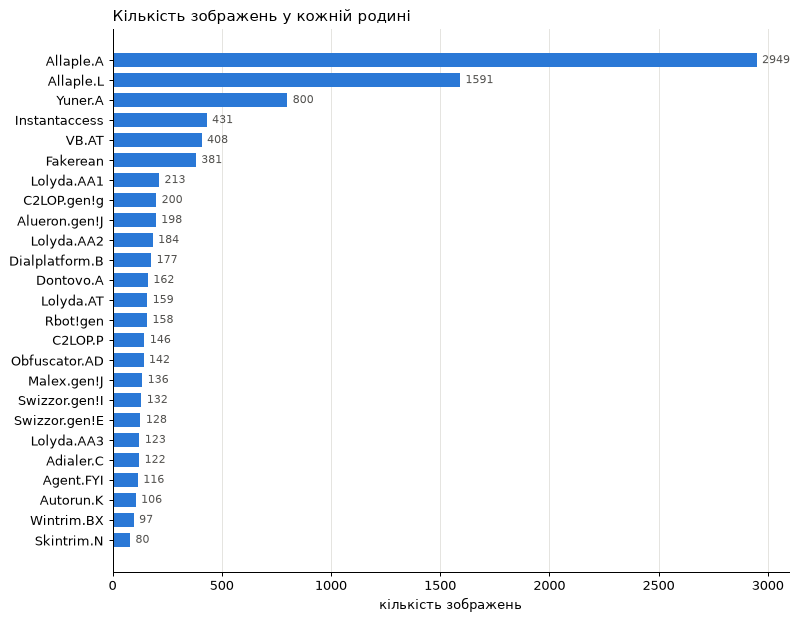

In [12]:
counts = malimg['family'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 7), dpi=90)
ax.barh(counts.index, counts.values, color='#2a78d6', height=0.7)
for i, v in enumerate(counts.values):
    ax.text(v + 25, i, str(v), va='center', fontsize=9, color='#52514e')
ax.set_title('Кількість зображень у кожній родині', loc='left', fontsize=12)
ax.set_xlabel('кількість зображень')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', color='#e5e4e0', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

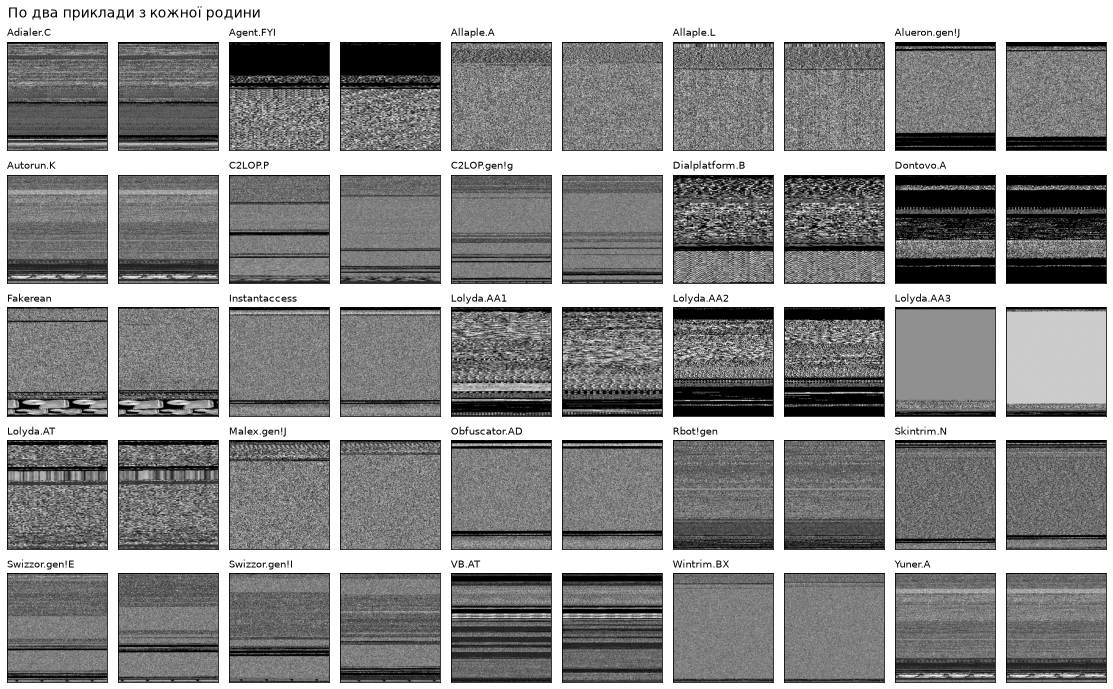

In [13]:
fig, axes = plt.subplots(5, 10, figsize=(16, 10), dpi=70)
families = sorted(malimg['family'].unique())
rng = np.random.default_rng(0)
for i, family in enumerate(families):
    files = malimg.loc[malimg['family'] == family, 'path'].values
    for k, f in enumerate(rng.choice(files, 2, replace=False)):
        ax = axes[i // 5, (i % 5) * 2 + k]
        ax.imshow(Image.open(f), cmap='gray', aspect='auto')   # aspect='auto': усі клітинки однакового розміру
        ax.set_xticks([])
        ax.set_yticks([])
        if k == 0:
            ax.set_title(family, loc='left', fontsize=10)
fig.suptitle('По два приклади з кожної родини', x=0.01, ha='left', fontsize=14)
plt.tight_layout()
plt.show()

Зображення різних родин справді помітно відрізняються. У Lolyda.AA1, Dialplatform.B, Dontovo.A чи VB.AT видно чіткі смуги й візерунки, у Lolyda.AA3 більшу частину займає однорідна сіра ділянка (довга послідовність однакових байтів), а у Fakerean є характерний візерунок унизу. Водночас Allaple.A, Allaple.L, Instantaccess чи Wintrim.BX схожі на рівномірний шум, що типово для стиснених або зашифрованих даних, і їх розрізняють лише тонкі деталі текстури та положення смуг.

Два приклади майже кожної родини дуже схожі між собою, тобто родина справді має свій **«відбиток»**. Помітно й інше. Yuner.A і Autorun.K виглядають майже однаково, а обидва приклади Yuner.A взагалі ідентичні. Чому так, з'ясується під час очищення даних.

### Очищення і вибірка

У датасеті багато повторів. Частина файлів збігається байт у байт, а ще частина відрізняється лише службовими даними PNG, тоді як самі пікселі однакові. Тому порівнюємо не файли, а зображення, тобто рахуємо хеш-суму MD5 від масиву пікселів. Якщо одна копія зображення потрапить у train, а інша в test, модель просто впізнає вже бачене, і оцінка вийде завищеною. Тому залишаємо лише одну копію кожного зображення. Родини, у яких після цього лишилося менше 10 різних зображень (MIN_UNIQUE), прибираємо, бо на кількох зображеннях не можна ні навчити модель, ні чесно її перевірити.

Далі обмежуємо кожну родину 300 зображеннями (MAX_PER_FAMILY). Без цього дві родини Allaple займали б майже половину датасету, модель вчилася б переважно на них, а навчання на звичайному процесорі тривало б у кілька разів довше. Для великих родин 300 зображень вибираємо випадково, але з фіксованим random_state, тому вибірка завжди однакова. Малі родини беремо повністю.

In [14]:
MAX_PER_FAMILY = 300
MIN_UNIQUE = 10

dedup = malimg.drop_duplicates('pixel_md5')
unique_counts = dedup['family'].value_counts()
dropped = unique_counts[unique_counts < MIN_UNIQUE].index.tolist()
print('Прибрані родини (менше', MIN_UNIQUE, 'різних зображень):', dropped)
dedup = dedup[~dedup['family'].isin(dropped)]
sample = pd.concat([g.sample(min(len(g), MAX_PER_FAMILY), random_state=42)    # великі родини обрізаємо до 300
                    for _, g in dedup.groupby('family')])
sample = sample.sort_values(['family', 'name']).reset_index(drop=True)

summary = pd.DataFrame({'файлів': malimg['family'].value_counts(),
                        'різних файлів': malimg.drop_duplicates('file_md5')['family'].value_counts(),
                        'різних зображень': unique_counts,
                        'у вибірці': sample['family'].value_counts()}).fillna(0).astype(int)
print('Різних файлів:', malimg['file_md5'].nunique(), ' різних зображень:', malimg['pixel_md5'].nunique(),
      ' родин у вибірці:', sample['family'].nunique(), ' зображень у вибірці:', len(sample))
summary.sort_values('файлів', ascending=False).T

Прибрані родини (менше 10 різних зображень): ['Yuner.A']
Різних файлів: 8444  різних зображень: 8019  родин у вибірці: 24  зображень у вибірці: 3839


family,Allaple.A,Allaple.L,Yuner.A,Instantaccess,VB.AT,Fakerean,Lolyda.AA1,C2LOP.gen!g,Alueron.gen!J,Lolyda.AA2,Dialplatform.B,Dontovo.A,Lolyda.AT,Rbot!gen,C2LOP.P,Obfuscator.AD,Malex.gen!J,Swizzor.gen!I,Swizzor.gen!E,Lolyda.AA3,Adialer.C,Agent.FYI,Autorun.K,Wintrim.BX,Skintrim.N
файлів,2949,1591,800,431,408,381,213,200,198,184,177,162,159,158,146,142,136,132,128,123,122,116,106,97,80
різних файлів,2949,1591,133,431,408,199,213,200,198,184,177,162,157,158,146,142,136,132,128,123,93,116,91,97,80
різних зображень,2949,1591,1,431,408,33,213,200,198,184,177,162,154,158,146,142,136,132,128,123,44,116,16,97,80
у вибірці,300,300,0,300,300,33,213,200,198,184,177,162,154,158,146,142,136,132,128,123,44,116,16,97,80


Очищення змінило датасет сильніше, ніж можна було очікувати. Із 9 339 файлів лише 8 444 відрізняються байтами, а різних зображень ще менше, 8 019. Найбільше повторів у Yuner.A, де всі 800 файлів дають **одне й те саме зображення**. Якби ми порівнювали лише байти файлів, то вважали б, що в Yuner.A є 133 різні зображення. Так само в Autorun.K зі 106 файлів лишилося 16 різних зображень, у Fakerean з 381 лише 33, а в Adialer.C зі 122 лише 44. До того ж зображення Yuner.A майже збігається із зображеннями Autorun.K, помітно відрізняються лише останні 13 рядків пікселів з 683.

Yuner.A прибираємо, тож далі працюємо з 24 родинами і 3 839 зображеннями. Без такого очищення копії одного зображення потрапили б і в train, і в test, і точність вийшла б штучно завищеною. Малі родини Autorun.K, Fakerean і Adialer.C залишаємо, але в test від них буде лише 3-6 зображень, тому їхні метрики слід сприймати обережно.

### Підготовка зображень

Усі зображення зменшуємо до 64 × 64 пікселі (змінна IMG_SIZE). Вихідні зображення мають різну ширину і висоту, а мережа приймає батч як тензор однакового розміру, тому кожне просто стискаємо до квадрата. Пропорції при цьому змінюються, але текстура і порядок смуг зберігаються, а саме за ними й розрізняються родини. Зображення один раз завантажуємо в пам'ять як тензор цілих чисел 0-255.

Зображення сірі, тобто мають один канал, а EfficientNet вчилася на кольорових фото з трьома каналами. Тому той самий канал повторюємо тричі, а значення нормуємо середніми і стандартними відхиленнями ImageNet, як того вимагає попередньо навчена модель. Для простої CNN робимо так само, щоб обидві моделі отримували однакові дані.

Ділимо дані на train, validation і test у пропорції 70/15/15 зі стратифікацією. Звичайні прийоми для фото (відзеркалення, поворот, обрізання) тут не мають сенсу, бо відзеркалене зображення відповідало б файлу з байтами у зворотному порядку, а такої програми не існує.

In [15]:
IMG_SIZE = 64
malware_classes = sorted(sample['family'].unique())
image_labels = np.array([malware_classes.index(f) for f in sample['family']])

images = torch.stack([
    torch.from_numpy(np.array(Image.open(f).convert('L').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)))
    for f in sample['path']
])
labels = torch.tensor(image_labels)
print('Тензор зображень:', images.shape, images.dtype)

idx_train_img, idx_rest = train_test_split(np.arange(len(labels)), test_size=0.3, stratify=image_labels, random_state=42)
idx_val_img, idx_test_img = train_test_split(idx_rest, test_size=0.5, stratify=image_labels[idx_rest], random_state=42)
print('Train:', len(idx_train_img), ' Validation:', len(idx_val_img), ' Test:', len(idx_test_img))

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


class MalwareDataset(Dataset):
    def __init__(self, indices):
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        x = (images[j].float() / 255).unsqueeze(0).repeat(3, 1, 1)   # 1 канал -> 3 однакові канали
        return (x - IMAGENET_MEAN) / IMAGENET_STD, labels[j]


def image_loaders(train_indices, batch_size=32):
    return (DataLoader(MalwareDataset(train_indices), batch_size=batch_size, shuffle=True),
            DataLoader(MalwareDataset(idx_val_img), batch_size=256),
            DataLoader(MalwareDataset(idx_test_img), batch_size=256))


train_loader_img, val_loader_img, test_loader_img = image_loaders(idx_train_img)

Тензор зображень: torch.Size([3839, 64, 64]) torch.uint8
Train: 2687  Validation: 576  Test: 576


### а) Проста CNN, навчена з нуля

**Згортковий шар** (Conv2d) проходить по зображенню маленьким фільтром 3 × 3 і в кожній позиції рахує зважену суму пікселів. Кожен фільтр навчається реагувати на свій шаблон, наприклад на край смуги, певну текстуру чи однорідну ділянку. Перші шари знаходять прості шаблони, наступні складають з них складніші. На відміну від MLP, той самий фільтр застосовується в усіх місцях зображення, тому параметрів набагато менше і шаблон розпізнається незалежно від того, де він трапився.

Мережа має 3 згорткові блоки. Кожен блок складається зі згортки, BatchNorm (нормалізує виходи шару і пришвидшує навчання), ReLU і MaxPool 2 × 2 (зменшує зображення вдвічі, залишаючи найсильніші відгуки). Кількість фільтрів росте від 32 до 128, а розмір зображення зменшується з 64 до 8. AdaptiveAvgPool усереднює кожну карту ознак до 3 × 3, і ці 128 × 9 = 1152 числа йдуть у повнозв'язаний шар, який видає по одному логіту для кожної родини. Dropout 0.3 під час навчання випадково вимикає 30 % входів повнозв'язаного шару, щоб мережа не покладалася на окремі ознаки.

In [16]:
class MalwareCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),     # 64 -> 32
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),    # 32 -> 16
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),  # 16 -> 8
            nn.AdaptiveAvgPool2d(3),                                                             # 8 -> 3
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 3 * 3, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


set_seed(42)
cnn = MalwareCNN(len(malware_classes)).to(device)
print(cnn)
print('Параметрів:', sum(p.numel() for p in cnn.parameters()))

MalwareCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=3)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(

In [17]:
CNN_EPOCHS = 20
criterion_img = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)
history_cnn = fit(cnn, train_loader_img, val_loader_img, optimizer, criterion_img, n_epochs=CNN_EPOCHS, print_every=2)

[01] train_loss=0.8204 | val_loss=0.2357
[02] train_loss=0.2132 | val_loss=0.1540
[04] train_loss=0.1121 | val_loss=0.1318
[06] train_loss=0.0673 | val_loss=0.0968
[08] train_loss=0.0534 | val_loss=0.0703
[10] train_loss=0.0527 | val_loss=0.0588
[12] train_loss=0.0317 | val_loss=0.0488
[14] train_loss=0.0180 | val_loss=0.0794
[16] train_loss=0.0275 | val_loss=0.0635
[18] train_loss=0.0173 | val_loss=0.0577
[20] train_loss=0.0127 | val_loss=0.0653
Час навчання: 142 с


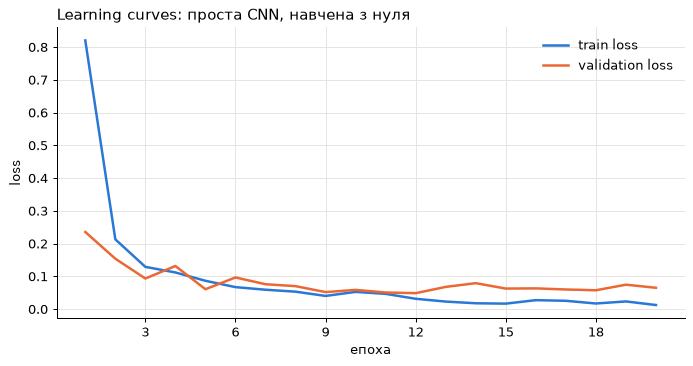

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.2), dpi=90)
plot_curves(ax, history_cnn, 'Learning curves: проста CNN, навчена з нуля')
plt.show()

Проста CNN навчається дуже швидко. Уже на 3-4-й епосі обидва loss опускаються приблизно до 0.10-0.13, а далі повільно знижуються. Train loss і validation loss ідуть поруч, тому **перенавчання практично немає**. Наприкінці train loss дорівнює 0.013, validation loss 0.065, і validation loss помітно не росте.

Після 5-ї епохи validation loss коливається в межах приблизно 0.05-0.10. Validation маленький (576 зображень), і кілька помилок у складних парах родин помітно змінюють середнє значення. Найнижчий validation loss 0.049 досягнуто на 12-й епосі.

### б) Попередньо навчена модель EfficientNet-B0

**Transfer learning** означає, що беремо модель, яку вже навчили на великому датасеті, і пристосовуємо її до своєї задачі. EfficientNet-B0 (Google, 2019) навчено на ImageNet, тобто на 1.28 млн фото 1000 класів. Її згорткові шари вже вміють знаходити краї, текстури і повторювані візерунки. Фото предметів наші зображення не нагадують, але текстури і смуги є і в них, тому частина цих ознак може бути корисною. EfficientNet-B0 обрали, бо вона маленька (5.3 млн параметрів) і швидко працює на звичайному процесорі.

Вихідний класифікатор _fc, розрахований на 1000 класів ImageNet, замінюємо новим лінійним шаром, у якого стільки виходів, скільки родин лишилося після очищення. Далі робимо fine-tuning. Спочатку заморожуємо всі шари (requires_grad = False), як у прикладі з практики, а потім знову дозволяємо навчання для останніх 6 із 16 блоків мережі та фінальної згортки _conv_head з її BatchNorm. Перші шари знаходять найпростіші ознаки (краї, перепади яскравості), які однаково корисні для будь-яких зображень, тому їх не чіпаємо. Останні шари відповідають за складні ознаки, налаштовані на предмети з ImageNet, і саме їх треба підлаштувати під зображення програм. Новий _fc вчиться з кроком 0.001, а розморожені шари з меншим кроком 0.0001, щоб не зіпсувати корисні ваги з ImageNet.

Ще одна важлива деталь стосується BatchNorm. Під час оцінки (model.eval()) кожен шар BatchNorm нормує ознаки накопиченими середнім і дисперсією, а в efficientnet_pytorch ці статистики оновлюються дуже повільно (momentum 0.01). Вони пораховані на фото ImageNet, а зображення програм мають зовсім інший розподіл яскравості. Без змін train loss швидко падає, а validation loss лишається високим, бо під час навчання мережа нормує ознаки статистиками поточного батчу, а під час оцінки старими статистиками ImageNet. Тому ставимо momentum 0.1 (стандартне значення в PyTorch), і статистики швидко підлаштовуються під наші дані.

In [19]:
from efficientnet_pytorch import EfficientNet


def make_effnet(n_unfrozen_blocks):
    model = EfficientNet.from_pretrained('efficientnet-b0')
    for p in model.parameters():
        p.requires_grad = False                                            
    model._fc = nn.Linear(model._fc.in_features, len(malware_classes))    
    for layer in model.modules():
        if isinstance(layer, nn.BatchNorm2d):
            layer.momentum = 0.1                                            
    param_groups = [{'params': list(model._fc.parameters()), 'lr': 1e-3}]
    if n_unfrozen_blocks > 0:
        layers = list(model._blocks[-n_unfrozen_blocks:]) + [model._conv_head, model._bn1]
        tuned = [p for layer in layers for p in layer.parameters()]
        for p in tuned:
            p.requires_grad = True                                        
        param_groups.append({'params': tuned, 'lr': 1e-4})
    return model.to(device), param_groups


set_seed(42)
N_UNFROZEN = 6
effnet, effnet_params = make_effnet(N_UNFROZEN)
total = sum(p.numel() for p in effnet.parameters())
trainable = sum(p.numel() for p in effnet.parameters() if p.requires_grad)
print('Новий класифікатор:', effnet._fc)
print(f'Блоків у мережі: {len(effnet._blocks)}, розморожено останні {N_UNFROZEN}')
print(f'Параметрів усього: {total:,}, навчаються: {trainable:,} ({trainable / total:.0%})')

Loaded pretrained weights for efficientnet-b0
Новий класифікатор: Linear(in_features=1280, out_features=24, bias=True)
Блоків у мережі: 16, розморожено останні 6
Параметрів усього: 4,038,292, навчаються: 3,395,056 (84%)


In [20]:
EFFNET_EPOCHS = 10
optimizer = torch.optim.Adam(effnet_params)
history_effnet = fit(effnet, train_loader_img, val_loader_img, optimizer, criterion_img, n_epochs=EFFNET_EPOCHS)

[01] train_loss=1.2192 | val_loss=0.4993
[02] train_loss=0.3576 | val_loss=0.2134
[03] train_loss=0.2117 | val_loss=0.2225
[04] train_loss=0.1550 | val_loss=0.1601
[05] train_loss=0.1205 | val_loss=0.1992
[06] train_loss=0.1043 | val_loss=0.2306
[07] train_loss=0.0885 | val_loss=0.1133
[08] train_loss=0.0729 | val_loss=0.0988
[09] train_loss=0.0618 | val_loss=0.1814
[10] train_loss=0.0542 | val_loss=0.3724
Час навчання: 160 с


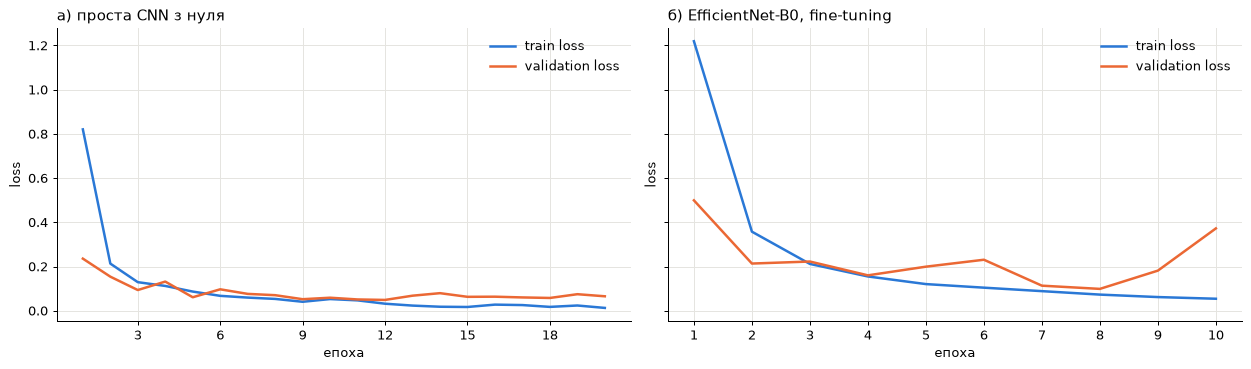

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), dpi=90, sharey=True)
plot_curves(axes[0], history_cnn, 'а) проста CNN з нуля')
plot_curves(axes[1], history_effnet, 'б) EfficientNet-B0, fine-tuning')
plt.tight_layout()
plt.show()

EfficientNet теж швидко знижує train loss, але її validation loss поводиться нестабільно. Він падає до 0.16 на 4-й епосі, потім зростає до 0.23, знову опускається до мінімуму 0.099 на 8-й епосі, а на 10-й підскакує до 0.37, хоча train loss весь час рівномірно падає (0.054 на 10-й епосі). Великий розрив наприкінці означає перенавчання, яке починається після 8-ї епохи.

Мережа має 3.4 млн параметрів, що навчаються, тобто приблизно в 28 разів більше, ніж проста CNN (121 тис.), а зображень у train лише 2 687. До того ж EfficientNet розрахована на фото 224 × 224, а на вході 64 × 64 її остання карта ознак має розмір лише 2 × 2. Тут явно допоміг би early stopping, тобто збереження моделі з 8-ї епохи.

Для порівняння навчимо й варіант як у прикладі з практики, де заморожено всі шари і навчається лише новий _fc. Тоді EfficientNet працює просто як готовий екстрактор ознак, а вчиться лише лінійний класифікатор над ними. Так видно, наскільки придатні ознаки ImageNet для зображень програм без жодного донавчання.

In [22]:
set_seed(42)
effnet_frozen, frozen_params = make_effnet(n_unfrozen_blocks=0)
print('Параметрів, що навчаються:', sum(p.numel() for p in effnet_frozen.parameters() if p.requires_grad))
optimizer = torch.optim.Adam(frozen_params)
history_frozen = fit(effnet_frozen, train_loader_img, val_loader_img, optimizer, criterion_img, n_epochs=EFFNET_EPOCHS, print_every=2)

Loaded pretrained weights for efficientnet-b0
Параметрів, що навчаються: 30744
[01] train_loss=1.4715 | val_loss=0.9166
[02] train_loss=0.6149 | val_loss=0.4785
[04] train_loss=0.3761 | val_loss=0.3702
[06] train_loss=0.3338 | val_loss=0.4534
[08] train_loss=0.2806 | val_loss=0.2590
[10] train_loss=0.2508 | val_loss=0.4046
Час навчання: 100 с


### Порівняння якості

In [23]:
image_models = [('Проста CNN з нуля', cnn, history_cnn),
                ('EfficientNet-B0, fine-tuning', effnet, history_effnet),
                ('EfficientNet-B0, лише новий _fc', effnet_frozen, history_frozen)]
image_results = {}
for name, model, history in image_models:
    image_results[name] = predict(model, test_loader_img, device)

pd.DataFrame({name: {
    'accuracy (test)': accuracy_score(*image_results[name]),
    'macro F1 (test)': f1_score(*image_results[name], average='macro'),
    'параметрів навчається': sum(q.numel() for q in model.parameters() if q.requires_grad),
    'епох': len(history['val_loss']),
    'найкраща епоха за val loss': int(np.argmin(history['val_loss'])) + 1,
    'мінімальний val loss': min(history['val_loss']),
    'час навчання, с': history['time'],
} for name, model, history in image_models}).T.round(4)

,accuracy (test),macro F1 (test),параметрів навчається,епох,найкраща епоха за val loss,мінімальний val loss,"час навчання, с"
Проста CNN з нуля,0.9722,0.9696,121368.0,20.0,12.0,0.0488,142.0821
"EfficientNet-B0, fine-tuning",0.9427,0.9455,3395056.0,10.0,8.0,0.0988,160.4441
"EfficientNet-B0, лише новий _fc",0.9010,0.9010,30744.0,10.0,8.0,0.2590,99.7015


In [24]:
# F1 для кожної родини
per_class_f1 = pd.DataFrame({name: f1_score(*image_results[name], average=None, labels=range(len(malware_classes)))
                             for name, _, _ in image_models}, index=malware_classes)
per_class_f1.insert(0, 'фото в test', np.bincount(labels[idx_test_img].numpy(), minlength=len(malware_classes)))
per_class_f1.sort_values('Проста CNN з нуля').round(3)

,фото в test,Проста CNN з нуля,"EfficientNet-B0, fine-tuning","EfficientNet-B0, лише новий _fc"
Swizzor.gen!I,20,0.757,0.683,0.556
Swizzor.gen!E,19,0.842,0.706,0.438
C2LOP.P,22,0.851,0.833,0.784
C2LOP.gen!g,30,0.933,0.915,0.812
Lolyda.AA2,28,0.964,0.982,0.982
Lolyda.AA1,32,0.970,0.985,0.954
Malex.gen!J,20,0.974,0.923,0.850
Lolyda.AT,23,0.978,0.978,0.955
Alueron.gen!J,29,1.000,0.983,0.966
Autorun.K,3,1.000,1.000,0.857


In [25]:
for name in ['Проста CNN з нуля', 'EfficientNet-B0, fine-tuning']:
    print(f'===== {name}: найчастіші помилки =====')
    print(top_confusions(*image_results[name], malware_classes, n=6).to_string(index=False), '\n')

===== Проста CNN з нуля: найчастіші помилки =====
справжній клас передбачений клас  кількість
 Swizzor.gen!I           C2LOP.P          3
 Swizzor.gen!I     Swizzor.gen!E          3
 Swizzor.gen!E     Swizzor.gen!I          3
       C2LOP.P       C2LOP.gen!g          2
   C2LOP.gen!g           C2LOP.P          2
    Lolyda.AA2        Lolyda.AA1          1 

===== EfficientNet-B0, fine-tuning: найчастіші помилки =====
справжній клас передбачений клас  кількість
 Swizzor.gen!E     Swizzor.gen!I          7
     Allaple.L         Allaple.A          5
     Allaple.A         Allaple.L          3
 Swizzor.gen!I           C2LOP.P          3
   C2LOP.gen!g           C2LOP.P          3
 Swizzor.gen!I     Swizzor.gen!E          3 



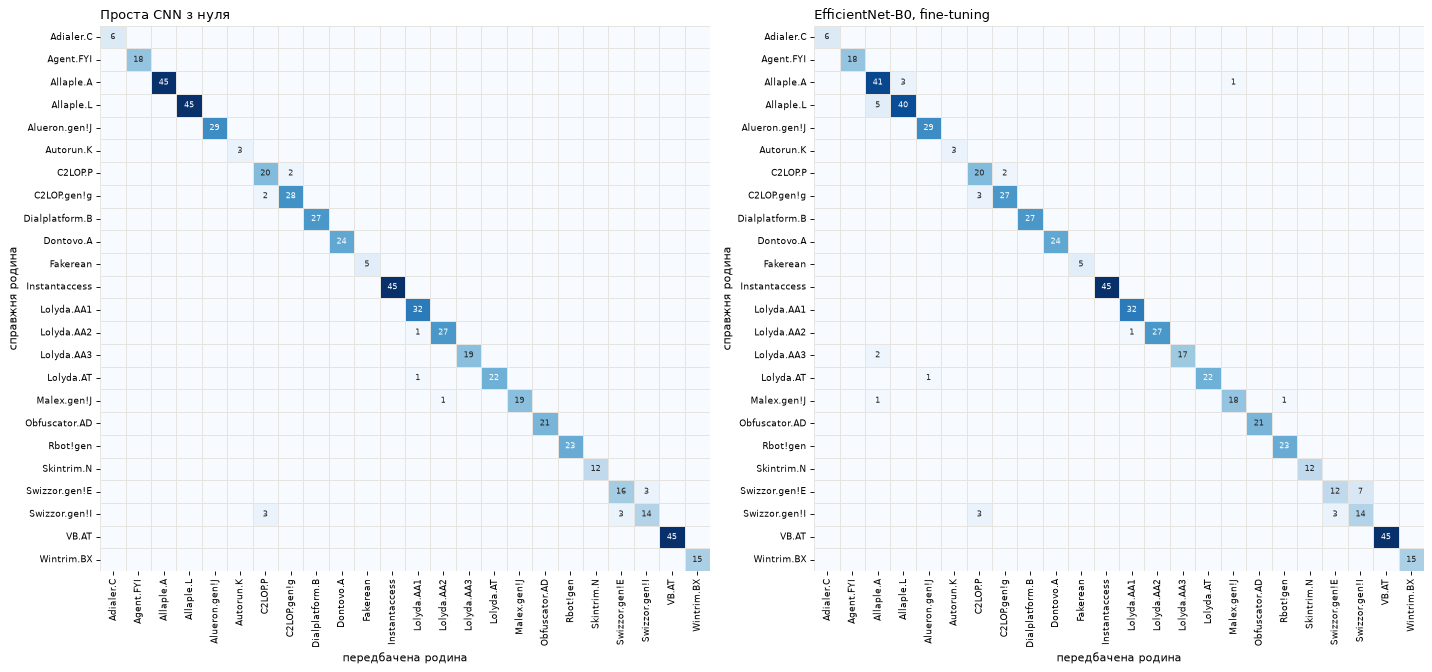

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8.5), dpi=80)
for ax, name in zip(axes, ['Проста CNN з нуля', 'EfficientNet-B0, fine-tuning']):
    t, p = image_results[name]
    cm = confusion_matrix(t, p, labels=range(len(malware_classes)))
    sns.heatmap(cm, annot=np.where(cm > 0, cm.astype(str), ''), fmt='', annot_kws={'fontsize': 7}, cmap='Blues', cbar=False,
                linewidths=0.5, linecolor='#e5e4e0', xticklabels=malware_classes, yticklabels=malware_classes, ax=ax)
    ax.set_title(name, loc='left', fontsize=12)
    ax.set_xlabel('передбачена родина')
    ax.set_ylabel('справжня родина')
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

Результат протилежний до очікуваного. Проста CNN з нуля виявилася найкращою (accuracy 0.972, macro F1 0.970), EfficientNet з fine-tuning має 0.943 і 0.946, а варіант із замороженою мережею лише 0.901. Проста CNN ще й навчається трохи швидше (142 с за 20 епох проти 160 с за 10 епох у EfficientNet).

Таблиця F1 по родинах показує, де саме помиляються моделі. Для 16 з 24 родин проста CNN має F1 1.0, і майже всі її помилки припадають на дві пари варіантів однієї родини. Між Swizzor.gen!E і Swizzor.gen!I вона помилилася 6 разів (і ще 3 зображення Swizzor.gen!I віднесла до C2LOP.P), а між C2LOP.P і C2LOP.gen!g 4 рази. Ці пари важкі для всіх моделей, бо варіанти однієї родини зібрані з дуже схожого коду. EfficientNet плутає ті самі пари, а крім того ще й Allaple.A з Allaple.L (8 помилок), які проста CNN розрізняє ідеально. Зображення Allaple.A мають ширину 256 пікселів, а Allaple.L 128, тому після стискання до 64 × 64 їхня текстура, ймовірно, має різний масштаб, і невелика CNN це вловлює.

Отже, на зображеннях програм перенесення знань з ImageNet не дає переваги. Ознаки, навчені на фото предметів (форми, частини об'єктів), мало пов'язані з текстурою байтів, тому заморожена мережа з ними дає лише 0.901. Fine-tuning частково це виправляє (+4 пункти), але невелика мережа, навчена саме на цих даних, все одно краща.

### Вплив обсягу тренувальних даних

Навчимо просту CNN і EfficientNet з fine-tuning заново на 10 %, 25 % і 50 % тренувальних зображень (зі стратифікацією, тобто частка кожної родини зберігається) і порівняємо accuracy на тому самому test. Для 100 % беремо результат моделей, які вже навчили вище. Решта налаштувань без змін. Це найдовша клітинка ноутбука.

In [27]:
def train_quietly(model, train_loader, params, n_epochs):
    optimizer = torch.optim.Adam(params, lr=1e-3)
    for epoch in range(n_epochs):
        train_one_epoch(model, train_loader, optimizer, criterion_img, device)
    t, p = predict(model, test_loader_img, device)
    return accuracy_score(t, p)


size_results = []
for frac in [0.1, 0.25, 0.5]:
    subset, _ = train_test_split(idx_train_img, train_size=frac, stratify=image_labels[idx_train_img], random_state=42)
    loader, _, _ = image_loaders(subset)

    set_seed(42)
    small_cnn = MalwareCNN(len(malware_classes)).to(device)
    acc_cnn = train_quietly(small_cnn, loader, small_cnn.parameters(), CNN_EPOCHS)

    set_seed(42)
    small_eff, small_params = make_effnet(N_UNFROZEN)
    acc_eff = train_quietly(small_eff, loader, small_params, EFFNET_EPOCHS)

    size_results.append({'частка train': frac, 'зображень у train': len(subset),
                         'проста CNN': acc_cnn, 'EfficientNet-B0 (fine-tuning)': acc_eff})
    print(f'{frac:>4.0%} ({len(subset)} зображень): CNN {acc_cnn:.3f}, EfficientNet {acc_eff:.3f}')

# 100 % - моделі, навчені вище на всьому train
size_results.append({'частка train': 1.0, 'зображень у train': len(idx_train_img),
                     'проста CNN': accuracy_score(*image_results['Проста CNN з нуля']),
                     'EfficientNet-B0 (fine-tuning)': accuracy_score(*image_results['EfficientNet-B0, fine-tuning'])})

size_df = pd.DataFrame(size_results).set_index('частка train')
size_df.round(4)

Loaded pretrained weights for efficientnet-b0
 10% (268 зображень): CNN 0.951, EfficientNet 0.858
Loaded pretrained weights for efficientnet-b0
 25% (671 зображень): CNN 0.953, EfficientNet 0.892
Loaded pretrained weights for efficientnet-b0
 50% (1343 зображень): CNN 0.953, EfficientNet 0.929


,зображень у train,проста CNN,EfficientNet-B0 (fine-tuning)
частка train,,,
0.10,268,0.9514,0.8576
0.25,671,0.9531,0.8924
0.50,1343,0.9531,0.9288
1.00,2687,0.9722,0.9427


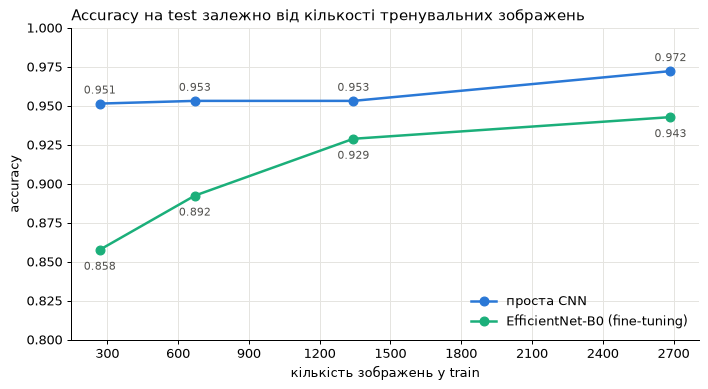

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=90)
for col, color in [('проста CNN', '#2a78d6'), ('EfficientNet-B0 (fine-tuning)', '#1baf7a')]:
    ax.plot(size_df['зображень у train'], size_df[col], color=color, marker='o', markersize=7, linewidth=2, label=col)
    offset = 8 if col == 'проста CNN' else -16          # підписи CNN над точками, EfficientNet під ними
    for x, v in zip(size_df['зображень у train'], size_df[col]):
        ax.annotate(f'{v:.3f}', (x, v), textcoords='offset points', xytext=(0, offset), ha='center', fontsize=9, color='#52514e')
ax.set_title('Accuracy на test залежно від кількості тренувальних зображень', loc='left', fontsize=12)
ax.set_xlabel('кількість зображень у train')
ax.set_ylabel('accuracy')
ax.set_ylim(0.8, 1.0)
ax.legend(frameon=False, loc='lower right')
clean_axes(ax)
plt.show()

Проста CNN майже не залежить від обсягу даних. Уже з 268 зображень (10 % train, у середньому 11 на родину) вона має 0.951, а на всіх 2 687 зображеннях ненабагато більше, 0.972. EfficientNet, навпаки, сильно залежить від кількості даних. З 268 зображень вона має лише 0.858 і тільки на повному train наближається до простої CNN (0.943).

Тобто для цієї задачі попередньо навчена модель потребує **більше даних**, а не менше. Їй треба переналаштувати 3.4 млн параметрів під зовсім новий тип зображень, а маленькій CNN досить кількох прикладів, бо родини відрізняються чіткими текстурами. Кожна точка отримана з одного запуску, тому різниця в 1-2 пункти між сусідніми точками може бути випадковою, але загальна картина однозначна.

### Висновки до завдання 2

У другому завданні ми класифікували зображення шкідливих програм з датасету Malimg за родинами. Спершу датасет довелося ретельно очистити. З 9 339 файлів різних зображень лише 8 019, а 800 файлів родини Yuner.A виявилися одним і тим самим зображенням, тому цю родину прибрали і працювали з 24 родинами (3 839 зображень після обмеження до 300 на родину). Проста CNN з трьома згортковими блоками (121 тис. параметрів), навчена з нуля, за 20 епох отримала accuracy 0.972 і не перенавчилася. EfficientNet-B0, попередньо навчена на ImageNet, з новим класифікатором і донавченими останніми 6 блоками дала 0.943, а з повністю замороженою мережею лише 0.901. Її validation loss був нестабільним, і після 8-ї епохи почалося перенавчання.

Transfer learning допомагає не завжди. Він дає перевагу, коли нові зображення схожі на ті, на яких вчилася модель, а зображення байтів програм зовсім не схожі на фото предметів. Тут попередньо навчена модель програла простій CNN і за якістю, і за стабільністю навчання, і за потребою в даних (на 10 % train 0.858 проти 0.951). Обидві моделі найчастіше плутали варіанти однієї родини (Swizzor.gen!E і Swizzor.gen!I, C2LOP.P і C2LOP.gen!g), які й на око майже не відрізняються. Для такої задачі краще обрати невелику мережу, навчену з нуля, і особливу увагу приділити очищенню даних від дублікатів.

## 3) Нейронні мережі для класифікації текстів

### Дані з Lab 2

Беремо той самий датасет, що й у Lab 2, YouTube Spam Collection https://archive.ics.uci.edu/dataset/380/youtube+spam+collection, тобто коментарі під п'ятьма кліпами YouTube з мітками spam і ham. Дублікати тексту видаляємо, як і в Lab 2.

In [29]:
YT_DIR = Path('youtube_spam')
UCI_URL = 'https://archive.ics.uci.edu/static/public/380/youtube+spam+collection.zip'
MIRROR_URL = 'https://raw.githubusercontent.com/sahilbhange/YouTube-comments-Spam-Detector/master/'
YT_FILES = ['Youtube01-Psy.csv', 'Youtube02-KatyPerry.csv', 'Youtube03-LMFAO.csv',
            'Youtube04-Eminem.csv', 'Youtube05-Shakira.csv']


def find_csv(folder):
    files = {}
    for f in sorted(folder.rglob('Youtube0*.csv')):
        if '__MACOSX' not in f.parts:
            files.setdefault(f.name, f)
    return list(files.values())


if len(find_csv(YT_DIR)) < len(YT_FILES):
    YT_DIR.mkdir(exist_ok=True)
    try:
        zip_path = YT_DIR / 'youtube_spam_collection.zip'
        urllib.request.urlretrieve(UCI_URL, zip_path)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(YT_DIR)
        zip_path.unlink()
    except Exception as error:
        print(f'UCI недоступний ({error}), беру файли з копії на GitHub')
    if len(find_csv(YT_DIR)) < len(YT_FILES):
        for name in YT_FILES:
            urllib.request.urlretrieve(MIRROR_URL + name, YT_DIR / name)

yt = pd.concat([pd.read_csv(f) for f in find_csv(YT_DIR)], ignore_index=True)
yt = yt.drop_duplicates(subset='CONTENT', ignore_index=True)
print(f'Коментарів без дублікатів: {len(yt):,}')
print(yt['CLASS'].map({0: 'ham', 1: 'spam'}).value_counts().to_string())

Коментарів без дублікатів: 1,760
CLASS
ham     919
spam    841


### Передобробка для нейронної мережі

Передобробка тут відрізняється від Lab 2. Для TF-IDF порядок слів не мав значення, і стоп-слова ми видаляли. Рекурентна мережа читає текст слово за словом, тому порядок важливий, а службові слова (you, my, this) теж несуть зміст у фразах на кшталт «check out my channel». GloVe теж навчався на текстах зі стоп-словами. Тому стоп-слова залишаємо, а решту очищення робимо як у Lab 2 (HTML-коди й теги, посилання замінюємо словом url, нижній регістр, лише латинські літери).

Далі йдуть чотири кроки, яких вимагає завдання. Токенізація розбиває текст на окремі слова (токени), у нас просто за пробілами, бо після очищення в тексті лишилися тільки літери й пробіли. **Словник** будуємо лише з train і додаємо два службові токени, [PAD] з індексом 0 для доповнення і [UNK] з індексом 1 для слів, яких немає в словнику. Перетворення в індекси замінює кожне слово його номером у словнику. Padding/truncation приводить усі послідовності до однакової довжини MAX_LEN, бо мережа приймає батч як прямокутний тензор. Короткі коментарі доповнюємо нулями ([PAD]) справа, довгі обрізаємо.

In [30]:
URL_PATTERN = re.compile(r'https?://\S+|www\.\S+|\b[\w-]+\.(?:com|net|org|tk|pl|ly|be|ru|us|info|co|me|tv)\b\S*|/watch\?v=\S+')


def tokenize(text):
    text = html.unescape(text).replace('﻿', ' ')
    text = re.sub(r'<[^>]+>', ' ', text).lower()
    text = URL_PATTERN.sub(' url ', text)
    text = re.sub(r"['’]", '', text)
    text = re.sub(r'[^a-z]+', ' ', text)
    return text.split()


yt['tokens'] = yt['CONTENT'].map(tokenize)
yt = yt[yt['tokens'].map(len) > 0].reset_index(drop=True)
print(f'Коментарів після очищення: {len(yt):,}\n')
for _, row in yt.sample(3, random_state=1).iterrows():
    print(row['CONTENT'].replace('﻿', '')[:100], '\n   ->', row['tokens'][:15], '\n')

Коментарів після очищення: 1,749

Wanna Laugh??? Please SUBSCRIBE to our channel!!! 
   -> ['wanna', 'laugh', 'please', 'subscribe', 'to', 'our', 'channel'] 

There are beautiful songs please subscribe 
   -> ['there', 'are', 'beautiful', 'songs', 'please', 'subscribe'] 

http://www.avaaz.org/po/petition/Youtube_Corporation_Fox_Broadcasting_Company_Anular_os_strikes_no_C 
   -> ['url'] 



Довжина коментаря в токенах, перцентилі 50/90/95/99: [8.0, 39.0, 59.0, 96.0]


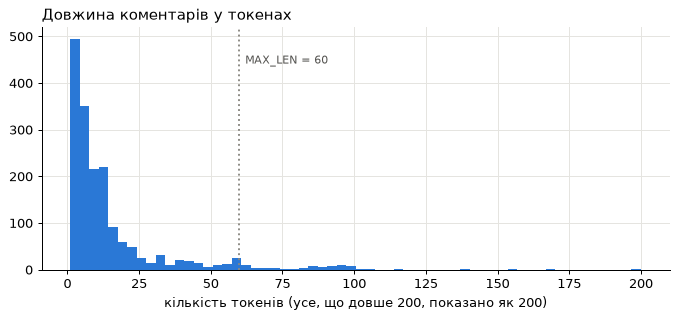

Коментарів, довших за MAX_LEN: 4.5%


In [31]:
lengths = yt['tokens'].map(len)
print('Довжина коментаря в токенах, перцентилі 50/90/95/99:', np.percentile(lengths, [50, 90, 95, 99]).round(0).tolist())

MAX_LEN = 60
fig, ax = plt.subplots(figsize=(9, 3.5), dpi=90)
ax.hist(lengths.clip(upper=200), bins=60, color='#2a78d6')
ax.axvline(MAX_LEN, color='#898781', linestyle=':', linewidth=1.5)
ax.text(MAX_LEN + 2, ax.get_ylim()[1] * 0.85, f'MAX_LEN = {MAX_LEN}', color='#52514e', fontsize=9)
ax.set_title('Довжина коментарів у токенах', loc='left', fontsize=12)
ax.set_xlabel('кількість токенів (усе, що довше 200, показано як 200)')
clean_axes(ax)
plt.show()
print(f'Коментарів, довших за MAX_LEN: {(lengths > MAX_LEN).mean():.1%}')

Більшість коментарів дуже короткі. Медіана становить 8 слів, і лише 10 % коментарів довші за 39 слів. Довжину MAX_LEN = 60 обрали приблизно на рівні 95-го перцентиля, тому обрізаються лише 4.5 % коментарів, і в них зникає тільки кінець. Перших 60 слів цілком достатньо, щоб зрозуміти, чи коментар є рекламою, а більший MAX_LEN лише збільшив би розмір тензорів.

In [32]:
y_text = yt['CLASS'].values
idx = np.arange(len(yt))
idx_train, idx_test = train_test_split(idx, test_size=0.2, stratify=y_text, random_state=42)
idx_tr, idx_val = train_test_split(idx_train, test_size=0.2, stratify=y_text[idx_train], random_state=42)
print('Train:', len(idx_tr), ' Validation:', len(idx_val), ' Test:', len(idx_test))

counter = Counter()
for tokens in yt['tokens'].iloc[idx_tr]:
    counter.update(tokens)

itos = ['[PAD]', '[UNK]'] + [word for word, _ in counter.most_common()]
stoi = {word: i for i, word in enumerate(itos)}
PAD_IDX, UNK_IDX = stoi['[PAD]'], stoi['[UNK]']
print('Розмір словника:', len(itos))
print('Найчастіші слова:', counter.most_common(12))


def encode(tokens):
    ids = [stoi.get(t, UNK_IDX) for t in tokens][:MAX_LEN]
    return ids + [PAD_IDX] * (MAX_LEN - len(ids))


X_text = torch.tensor([encode(t) for t in yt['tokens']], dtype=torch.long)
y_text_t = torch.tensor(y_text, dtype=torch.float32)
print('\nТензор усіх коментарів:', X_text.shape)
print('Приклад:', yt['tokens'].iloc[0][:8], '->', X_text[0, :8].tolist())
unk_share = (X_text[idx_val] == UNK_IDX).sum() / (X_text[idx_val] != PAD_IDX).sum()
print(f'Частка невідомих слів [UNK] у validation: {unk_share:.1%}')

text_loader = lambda ids, shuffle: DataLoader(TensorDataset(X_text[ids], y_text_t[ids]), batch_size=32, shuffle=shuffle)
train_loader_t = text_loader(idx_tr, True)
val_loader_t = text_loader(idx_val, False)
test_loader_t = text_loader(idx_test, False)

Train: 1119  Validation: 280  Test: 350
Розмір словника: 2755
Найчастіші слова: [('the', 458), ('i', 440), ('and', 381), ('this', 380), ('to', 356), ('you', 346), ('my', 305), ('a', 268), ('out', 259), ('check', 253), ('url', 224), ('it', 203)]

Тензор усіх коментарів: torch.Size([1749, 60])
Приклад: ['huh', 'anyway', 'check', 'out', 'this', 'you', 'tube', 'channel'] -> [1444, 2339, 11, 10, 5, 7, 444, 28]
Частка невідомих слів [UNK] у validation: 10.4%


### Модель з Embedding і BiLSTM

**Embedding** - це таблиця розміром (розмір словника × 100), у якій кожному слову відповідає вектор зі 100 чисел. Індекс слова просто вибирає свій рядок таблиці. Вектори є вагами мережі й навчаються разом з рештою моделі. У варіанті а) вони стартують з випадкових значень. padding_idx=0 означає, що [PAD] завжди має нульовий вектор і не навчається.

**LSTM** (Long Short-Term Memory) читає послідовність векторів слово за словом і на кожному кроці оновлює свій внутрішній стан. Завдяки «вентилям» вона вирішує, що з попередніх слів запам'ятати, а що забути, тому краще за звичайну RNN працює з довшими текстами. Двонаправлена LSTM (BiLSTM) читає коментар і зліва направо, і справа наліво. Останні стани обох напрямків склеюємо і подаємо в повнозв'язаний шар з одним виходом (логіт спаму).

Щоб LSTM не читала нулі-доповнення, використовуємо pack_padded_sequence. Він передає мережі справжню довжину кожного коментаря, і останній стан береться саме після останнього справжнього слова. Довжину рахуємо прямо в forward як кількість ненульових індексів.

Функція втрат BCEWithLogitsLoss (бінарна крос-ентропія) сама застосовує сигмоїду до логіта, тому в моделі сигмоїди немає, як і в прикладі з практики.

In [33]:
from torch.nn.utils.rnn import pack_padded_sequence


class SpamBiLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, pad_idx):
        super().__init__()
        self.pad_idx = pad_idx
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        lengths = (x != self.pad_idx).sum(dim=1).clamp(min=1).cpu()
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        _, (h, c) = self.lstm(packed)
        h_cat = torch.cat([h[-2], h[-1]], dim=1)   # останні стани прямого і зворотного напрямків
        return self.fc(h_cat).squeeze(1)


EMB_DIM, HIDDEN_DIM, TEXT_EPOCHS = 100, 64, 20
criterion_t = nn.BCEWithLogitsLoss()

set_seed(42)
lstm_random = SpamBiLSTM(len(itos), EMB_DIM, HIDDEN_DIM, PAD_IDX).to(device)
print(lstm_random)
print('Параметрів:', sum(p.numel() for p in lstm_random.parameters()))

SpamBiLSTM(
  (embedding): Embedding(2755, 100, padding_idx=0)
  (lstm): LSTM(100, 64, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Параметрів: 360621


### а) Embedding з випадковими вагами

In [34]:
optimizer = torch.optim.Adam(lstm_random.parameters(), lr=1e-3)
history_random = fit(lstm_random, train_loader_t, val_loader_t, optimizer, criterion_t, n_epochs=TEXT_EPOCHS)

[01] train_loss=0.5896 | val_loss=0.4751
[02] train_loss=0.3474 | val_loss=0.2643
[03] train_loss=0.2022 | val_loss=0.2638
[04] train_loss=0.1336 | val_loss=0.2219
[05] train_loss=0.0943 | val_loss=0.2073
[06] train_loss=0.0619 | val_loss=0.2209
[07] train_loss=0.0392 | val_loss=0.2543
[08] train_loss=0.0286 | val_loss=0.2860
[09] train_loss=0.0184 | val_loss=0.3149
[10] train_loss=0.0137 | val_loss=0.3315
[11] train_loss=0.0270 | val_loss=0.3059
[12] train_loss=0.0308 | val_loss=0.2804
[13] train_loss=0.0177 | val_loss=0.2918
[14] train_loss=0.0093 | val_loss=0.3156
[15] train_loss=0.0069 | val_loss=0.3352
[16] train_loss=0.0055 | val_loss=0.3478
[17] train_loss=0.0046 | val_loss=0.3529
[18] train_loss=0.0039 | val_loss=0.3576
[19] train_loss=0.0034 | val_loss=0.3646
[20] train_loss=0.0029 | val_loss=0.3494
Час навчання: 26 с


### б) Embedding, ініціалізований GloVe

**GloVe** (Global Vectors, Stanford) - це готові вектори слів, навчені на Вікіпедії та новинах (6 млрд слів). Слова, що трапляються в схожих контекстах, мають близькі вектори, тож модель одразу «знає», що, наприклад, subscribe і channel пов'язані, а song і music схожі. Беремо ту саму версію, що в прикладі з практики (glove.6B.100d, 400 тис. слів, вектори по 100 чисел), але завантажуємо з GitHub-архіву бібліотеки gensim (134 МБ замість 822 МБ zip). Файл завантажується один раз і зберігається поруч із ноутбуком.

Матрицю embedding збираємо під наш словник. Для слів, які є в GloVe, беремо готовий вектор, для решти випадковий, а для [PAD] нульовий. Як і в прикладі з практики, шар заморожуємо (freeze=True), тобто вектори не змінюються під час навчання, а вчаться лише LSTM і вихідний шар.

In [35]:
GLOVE_URL = 'https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz'
GLOVE_PATH = Path('glove-wiki-gigaword-100.gz')
if not GLOVE_PATH.exists():
    print('Завантажую GloVe (134 МБ)...')
    urllib.request.urlretrieve(GLOVE_URL, GLOVE_PATH)

glove = {}
with gzip.open(GLOVE_PATH, 'rt', encoding='utf8') as f:
    next(f)   # перший рядок містить кількість слів і розмірність
    for line in f:
        word, *values = line.rstrip().split(' ')
        if word in stoi:
            glove[word] = np.asarray(values, dtype=np.float32)

print(f'Слів словника, знайдених у GloVe: {len(glove)}/{len(itos)} = {len(glove) / len(itos):.1%}')
missing = [w for w, _ in counter.most_common() if w not in glove][:15]
print('Найчастіші слова, яких немає в GloVe:', missing)

Завантажую GloVe (134 МБ)...
Слів словника, знайдених у GloVe: 2439/2755 = 88.5%
Найчастіші слова, яких немає в GloVe: ['phenomenallyricshere', 'lneadw', 'suscribe', 'katycats', 'hahahahah', 'arive', 'soundsofsunday', 'katys', 'ociramma', 'spourmo', 'singlewave', 'eminems', 'fablife', 'vidios', 'chanell']


In [36]:
def glove_matrix(seed=42):
    rng = np.random.default_rng(seed)
    matrix = rng.normal(scale=0.1, size=(len(itos), EMB_DIM)).astype(np.float32)
    matrix[PAD_IDX] = 0.0
    for word, vector in glove.items():
        matrix[stoi[word]] = vector
    return torch.tensor(matrix)


def make_glove_model(seed=42):
    set_seed(seed)
    model = SpamBiLSTM(len(itos), EMB_DIM, HIDDEN_DIM, PAD_IDX)
    model.embedding = nn.Embedding.from_pretrained(glove_matrix(seed), freeze=True, padding_idx=PAD_IDX)
    return model.to(device)


lstm_glove = make_glove_model()
trainable = sum(p.numel() for p in lstm_glove.parameters() if p.requires_grad)
print(f'Параметрів, що навчаються: {trainable} (embedding заморожений)')

optimizer = torch.optim.Adam([p for p in lstm_glove.parameters() if p.requires_grad], lr=1e-3)
history_glove = fit(lstm_glove, train_loader_t, val_loader_t, optimizer, criterion_t, n_epochs=TEXT_EPOCHS)

Параметрів, що навчаються: 85121 (embedding заморожений)
[01] train_loss=0.5634 | val_loss=0.3584
[02] train_loss=0.2919 | val_loss=0.2415
[03] train_loss=0.2105 | val_loss=0.2244
[04] train_loss=0.1764 | val_loss=0.2251
[05] train_loss=0.1637 | val_loss=0.2200
[06] train_loss=0.1216 | val_loss=0.2219
[07] train_loss=0.1121 | val_loss=0.2151
[08] train_loss=0.0943 | val_loss=0.2952
[09] train_loss=0.1064 | val_loss=0.2427
[10] train_loss=0.0856 | val_loss=0.3023
[11] train_loss=0.0585 | val_loss=0.2873
[12] train_loss=0.0536 | val_loss=0.2467
[13] train_loss=0.0473 | val_loss=0.2812
[14] train_loss=0.0378 | val_loss=0.3019
[15] train_loss=0.0288 | val_loss=0.3537
[16] train_loss=0.0295 | val_loss=0.3770
[17] train_loss=0.0475 | val_loss=0.3277
[18] train_loss=0.0537 | val_loss=0.2688
[19] train_loss=0.0225 | val_loss=0.3323
[20] train_loss=0.0154 | val_loss=0.3524
Час навчання: 23 с


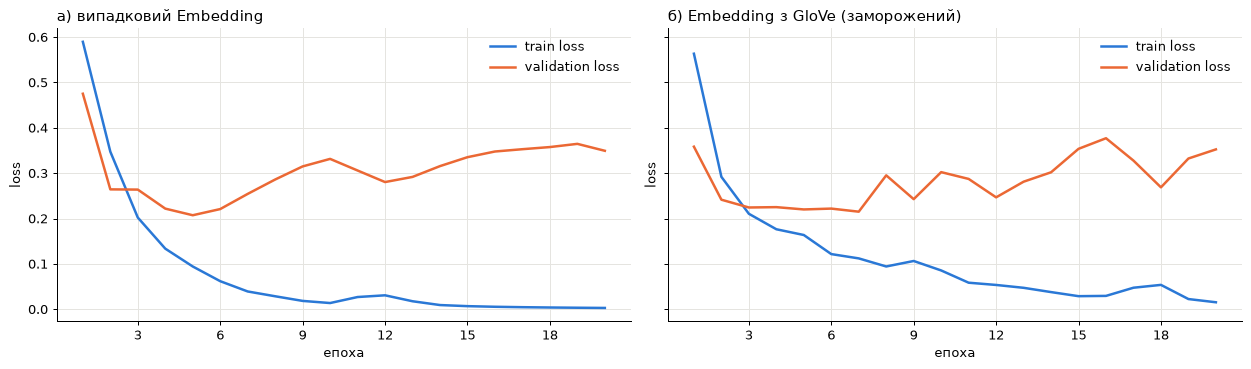

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), dpi=90, sharey=True)
plot_curves(axes[0], history_random, 'а) випадковий Embedding')
plot_curves(axes[1], history_glove, 'б) Embedding з GloVe (заморожений)')
plt.tight_layout()
plt.show()

У варіанті а train loss швидко падає майже до нуля (0.003 на 20-й епосі), а validation loss досягає мінімуму 0.207 вже на 5-й епосі і далі росте приблизно до 0.35-0.36. Це **явне перенавчання**. Мережа має 360 тис. параметрів, з них 275 тис. припадає на таблицю embedding, а тренувальних коментарів лише 1 119, тож після 5-ї епохи модель просто запам'ятовує train.

У варіанті б embedding заморожений, і навчаються лише 85 тис. параметрів LSTM і вихідного шару. Train loss падає повільніше, а validation loss довше тримається біля мінімуму, з 3-ї по 7-му епоху приблизно на рівні 0.22. Після цього він теж зростає і на 15-й, 16-й і 20-й епохах доходить до 0.35-0.38, тобто перенавчання тут починається пізніше, але наприкінці таке саме, як в а. Крива GloVe ще й нерівна, наприклад, на 16-й епосі validation loss 0.38, а на 18-й 0.27. Validation містить лише 280 коментарів, і кілька помилок помітно змінюють середній loss.

### Якість на test

Для порівняння на тому самому розбитті навчимо й модель з Lab 2 (TF-IDF + LinearSVC). Вона отримує ті самі тренувальні коментарі, але без стоп-слів, як у Lab 2.

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import precision_score, recall_score

texts = yt['tokens'].map(' '.join)
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words='english')
svc = LinearSVC().fit(tfidf.fit_transform(texts.iloc[idx_tr]), y_text[idx_tr])   # ті самі дані, на яких вчилися LSTM
svc_pred = svc.predict(tfidf.transform(texts.iloc[idx_test]))

text_results = {}
for name, model in [('BiLSTM, випадковий Embedding', lstm_random), ('BiLSTM, GloVe', lstm_glove)]:
    yt_true, yt_pred = predict(model, test_loader_t, device)
    text_results[name] = (yt_true, yt_pred)
text_results['TF-IDF + LinearSVC (Lab 2)'] = (y_text[idx_test], svc_pred)

pd.DataFrame({name: {'accuracy': accuracy_score(t, p), 'precision (spam)': precision_score(t, p),
                     'recall (spam)': recall_score(t, p), 'F1 (spam)': f1_score(t, p)}
              for name, (t, p) in text_results.items()}).T.round(4)

,accuracy,precision (spam),recall (spam),F1 (spam)
"BiLSTM, випадковий Embedding",0.9486,0.9464,0.9464,0.9464
"BiLSTM, GloVe",0.9571,0.9474,0.9643,0.9558
TF-IDF + LinearSVC (Lab 2),0.9257,0.9176,0.9286,0.9231


У цьому запуску модель з GloVe трохи краща. Її accuracy на test 0.957 проти 0.949, а F1 для спаму 0.956 проти 0.946. Precision в обох моделей майже однакова (0.947 і 0.946), тобто звичайні коментарі вони приймають за спам однаково рідко. Різниця в recall, бо модель з GloVe знаходить 96.4 % спаму, а модель з випадковим embedding 94.6 %.

Обидві нейронні мережі на 2-3 відсоткові пункти випереджають TF-IDF + LinearSVC з Lab 2 (0.926), навчений на тих самих 1 119 коментарях. LSTM враховує порядок слів, а TF-IDF лише рахує окремі слова та пари слів. Проте test містить лише 350 коментарів, тож різниця між двома LSTM становить лише 3 коментарі, і один запуск нейронної мережі ще нічого не доводить. Тому далі перевіряємо стабільність.

### Стабільність навчання

Один запуск нейронної мережі залежить від випадкової ініціалізації ваг і порядку батчів. На малому датасеті різниця між запусками може бути порівнянною з різницею між моделями. Тому навчимо кожну модель ще 5 разів з різними seed і подивимося на середнє й розкид accuracy на test, а також на розкид validation loss між запусками.

In [39]:
def run_text_model(kind, seed):
    if kind == 'glove':
        model = make_glove_model(seed)
    else:
        set_seed(seed)
        model = SpamBiLSTM(len(itos), EMB_DIM, HIDDEN_DIM, PAD_IDX).to(device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)
    history = {'val_loss': []}
    for epoch in range(TEXT_EPOCHS):
        train_one_epoch(model, train_loader_t, optimizer, criterion_t, device)
        history['val_loss'].append(evaluate_one_epoch(model, val_loader_t, criterion_t, device))
    t, p = predict(model, test_loader_t, device)
    return history['val_loss'], accuracy_score(t, p), f1_score(t, p)


seeds = [0, 1, 2, 3, 4]
stability = {}
for kind, name in [('random', 'випадковий Embedding'), ('glove', 'GloVe')]:
    runs = [run_text_model(kind, s) for s in seeds]
    stability[name] = {
        'val_loss': np.array([r[0] for r in runs]),
        'accuracy': np.array([r[1] for r in runs]),
        'f1': np.array([r[2] for r in runs]),
    }

pd.DataFrame({name: {'accuracy, середнє': s['accuracy'].mean(), 'accuracy, std': s['accuracy'].std(),
                     'accuracy, мін': s['accuracy'].min(), 'accuracy, макс': s['accuracy'].max(),
                     'F1 (spam), середнє': s['f1'].mean()}
              for name, s in stability.items()}).T.round(4)

,"accuracy, середнє","accuracy, std","accuracy, мін","accuracy, макс","F1 (spam), середнє"
випадковий Embedding,0.9371,0.0129,0.9171,0.9543,0.9353
GloVe,0.9549,0.0028,0.9514,0.9571,0.9536


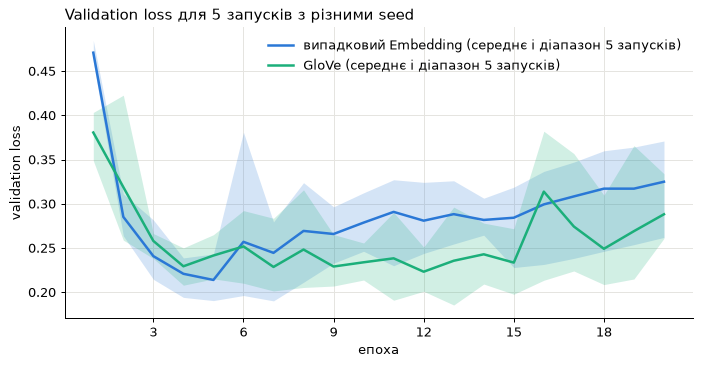

In [40]:
fig, ax = plt.subplots(figsize=(9, 4.2), dpi=90)
for (name, s), color in zip(stability.items(), ['#2a78d6', '#1baf7a']):
    epochs = range(1, TEXT_EPOCHS + 1)
    ax.fill_between(epochs, s['val_loss'].min(0), s['val_loss'].max(0), color=color, alpha=0.2, linewidth=0)
    ax.plot(epochs, s['val_loss'].mean(0), color=color, linewidth=2, label=f'{name} (середнє і діапазон 5 запусків)')
ax.set_title('Validation loss для 5 запусків з різними seed', loc='left', fontsize=12)
ax.set_xlabel('епоха')
ax.set_ylabel('validation loss')
ax.legend(frameon=False)
clean_axes(ax)
plt.show()

За 5 запусків GloVe дає вищу середню accuracy (0.955 проти 0.937) і у 4-5 разів менший розкид (std 0.003 проти 0.013). Навіть найгірший запуск з GloVe (0.951) кращий за середній запуск з випадковим embedding (0.937).

На графіку середній validation loss моделі з випадковим embedding після 5-ї епохи майже весь час росте і наприкінці доходить приблизно до 0.33, а діапазон між запусками сягає 0.27-0.37. У GloVe середній loss до 15-ї епохи тримається на рівні 0.22-0.25 і лише потім піднімається до 0.25-0.31, тобто перенавчання починається пізніше і слабше. Отже, перевага GloVe, яку видно вже в одному запуску, підтверджується в середньому результаті і особливо в стабільності. Випадкові вектори щоразу вчаться по-різному з малої кількості прикладів, а вектори GloVe однакові в кожному запуску, і модель спирається на вже відому схожість слів.

### Висновки до завдання 3

У третьому завданні перетворили коментарі YouTube на послідовності індексів (токенізація, словник з train, індекси, padding до 60 токенів) і навчили двонаправлену LSTM у двох варіантах. Обидві моделі навчаються швидко і вже на 5-7-й епосі validation loss опускається приблизно до 0.21-0.22. Модель з випадковим embedding далі сильно перенавчається, бо має вивчити 275 тис. ваг embedding лише з 1 119 коментарів. З замороженим GloVe навчається вчетверо менше параметрів, перенавчання починається пізніше і в середньому слабше, а результат стабільніший. Середня accuracy за 5 запусків становить 0.955 проти 0.937, std 0.003 проти 0.013.

Отже, попередньо навчені embedding найбільше допомагають на малих датасетах, бо приносять знання про мову з мільярдів слів, яких немає в 1 119 коментарях. Обидві LSTM перевершили TF-IDF + LinearSVC з Lab 2 на тих самих даних (0.949 і 0.957 проти 0.926 на test). Різниця невелика, тому для такої простої задачі лінійна модель на TF-IDF лишається гарною швидкою альтернативою. Для кращого результату нейронної мережі варто зупиняти навчання за найкращим validation loss (early stopping), бо після 5-ї епохи модель з випадковим embedding лише перенавчається.

## Загальні висновки

У цій роботі ми навчили в PyTorch нейронні мережі трьох типів для трьох типів даних і порівняли їх з класичними моделями з попередніх лабораторних.

Для табличних даних N-BaIoT повнозв'язана мережа (accuracy 0.892) не перевершила класичні алгоритми. Ознаки трафіку вже готові й мають порогову структуру, тому Random Forest з Lab 1 (0.9995) працює краще, швидше і не потребує стількох налаштувань. Для зображень шкідливих програм Malimg згорткова мережа знаходить ознаки прямо з пікселів, і проста CNN з нуля отримала 0.972. Попередньо навчена EfficientNet-B0 тут програла (0.943), бо ознаки з фото ImageNet погано переносяться на текстуру байтів. Для текстів YouTube Spam BiLSTM трохи перевершила TF-IDF + LinearSVC з Lab 2 (0.949 і 0.957 проти 0.926), а готові вектори GloVe зробили навчання стабільнішим (std accuracy 0.003 проти 0.013).

Попередньо навчені компоненти допомагають лише тоді, коли знання з великого датасету стосуються нової задачі. Вектори GloVe навчені на звичайних англійських текстах, і коментарі YouTube теж є такими текстами, тому вони допомогли. Фото ImageNet мало схожі на зображення програм, тому EfficientNet поступилася маленькій CNN. Learning curves у кожному завданні показували, чи є перенавчання (розрив між train loss і validation loss), і момент, коли навчання варто зупиняти. Нейронна мережа не є універсально кращим вибором, а в кожному завданні велику роль відіграли особливості даних, як-от час запису в ознаках N-BaIoT і дублікати в Malimg.